In [ ]:
#imports
import pandas as pd
import numpy as np
import pathlib

import sklearn.preprocessing as preprocessing
from sklearn import linear_model, metrics, model_selection
from sklearn.model_selection import train_test_split

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_theme(style='ticks', context='talk')
sns.despine()

#import colorcet as cc

<Figure size 640x480 with 0 Axes>

In [2]:
#define same bool
save = False

#define path
data_path = pathlib.Path(r'..\processed_data')

predict_ahead = 1

#define save path
save_path = pathlib.Path(r'..\processed_data')

#define task
task_df = pd.read_csv('sine_wave_25_min.csv', index_col=0)

#plotting paras
colours = ['#069DC7','#A02B93', '#FFC000']
alphas = [1, 0.8, 0.8]

In [3]:
def plot_data(axes, data_df, a, colour):
    
    #plot prediciton on first axis
    sns.lineplot(data = data_df, x = data_df['forecast time (s)']/60, y = data_df['y predict'], 
                #hue = 'dataset', 
                style = data_df['dataset'],
                color = colour,
                markers=False, dashes = False,ax=axes[0], legend = False,
                alpha = a,
                lw = 3)
    
    #plot ASE on second axis
    sns.lineplot(x = data_df['forecast time (s)']/60, y = data_df['ase'], 
                #hue = 'dataset', 
                color = colour,
                style = data_df['dataset'], markers=False, dashes = False,ax=axes[1], legend = False,
                alpha = a,
                lw = 3)

    




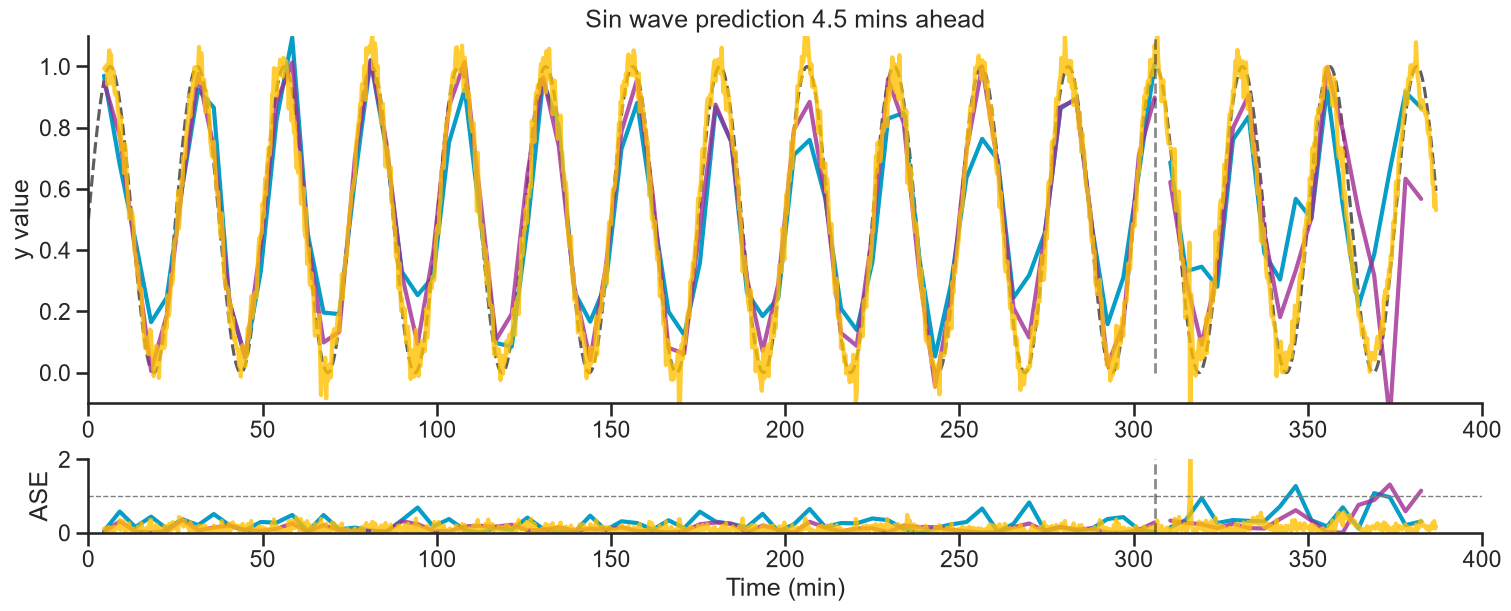

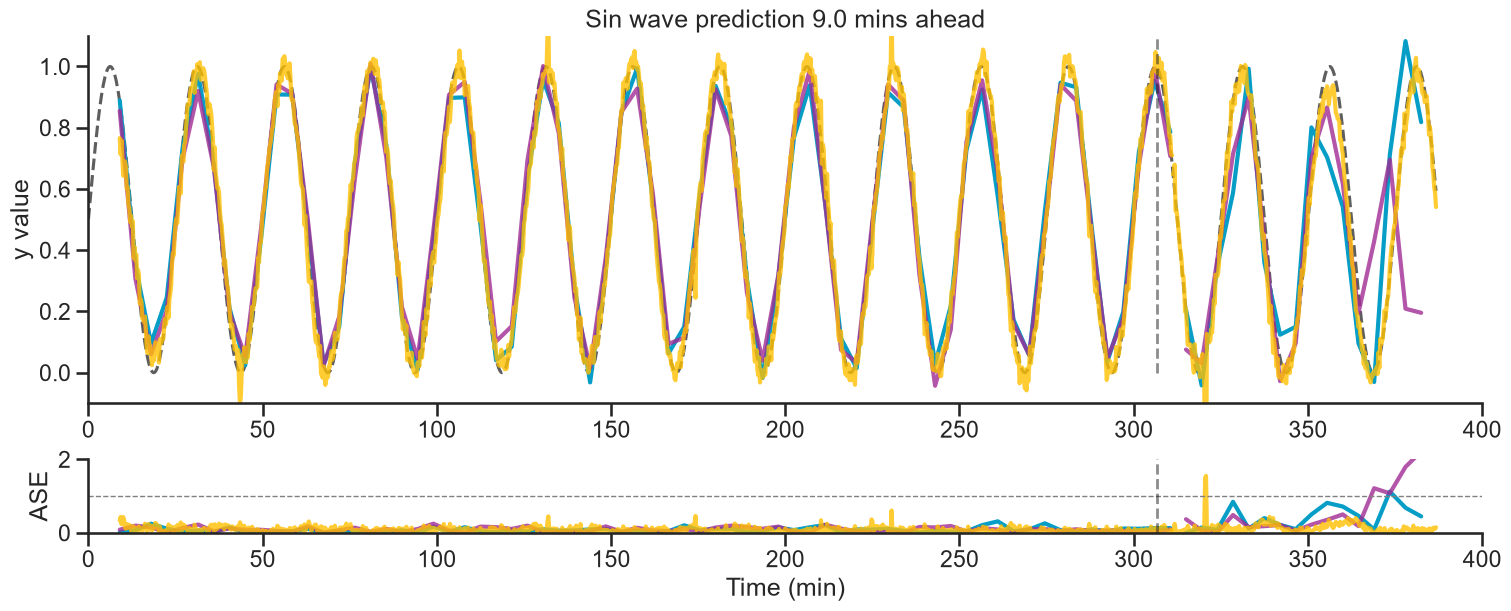

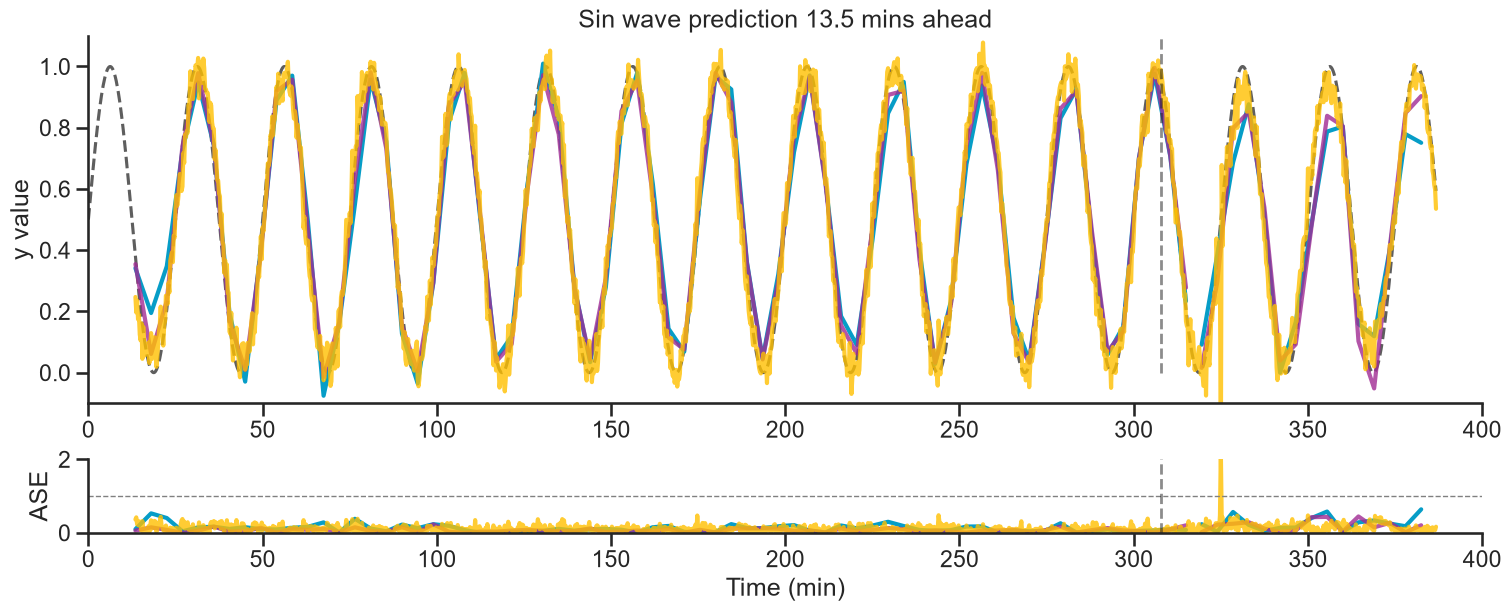

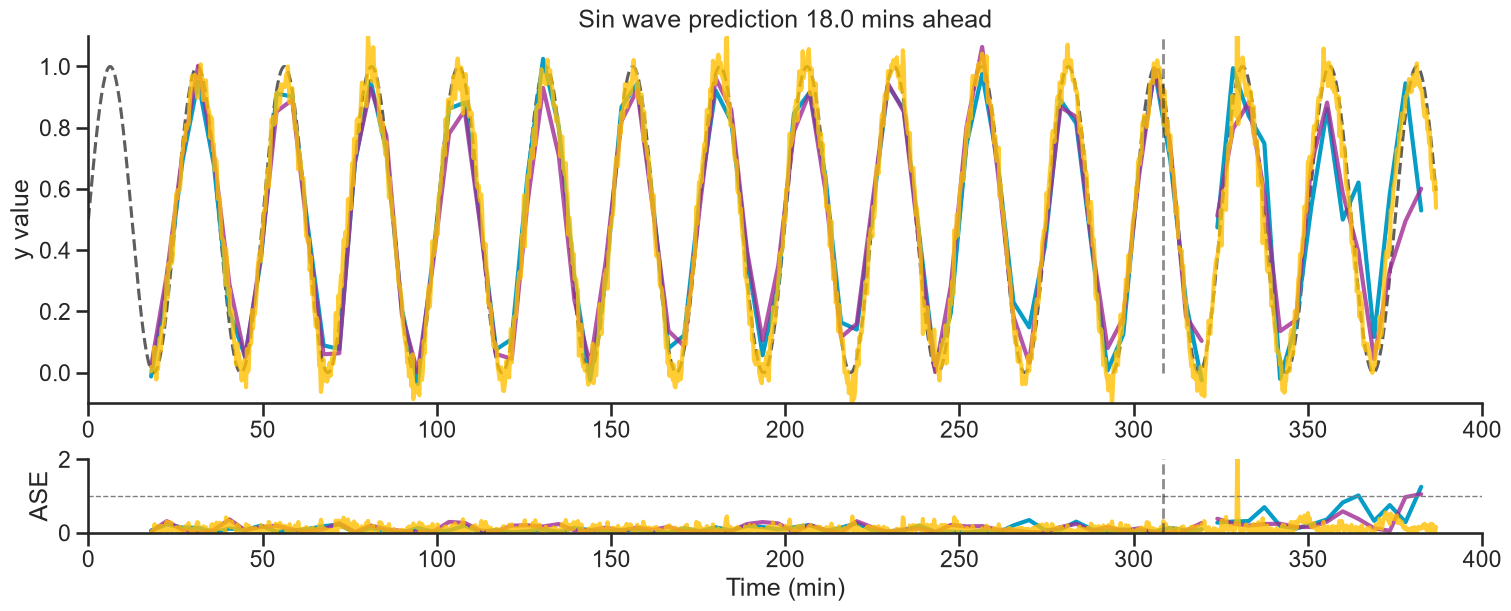

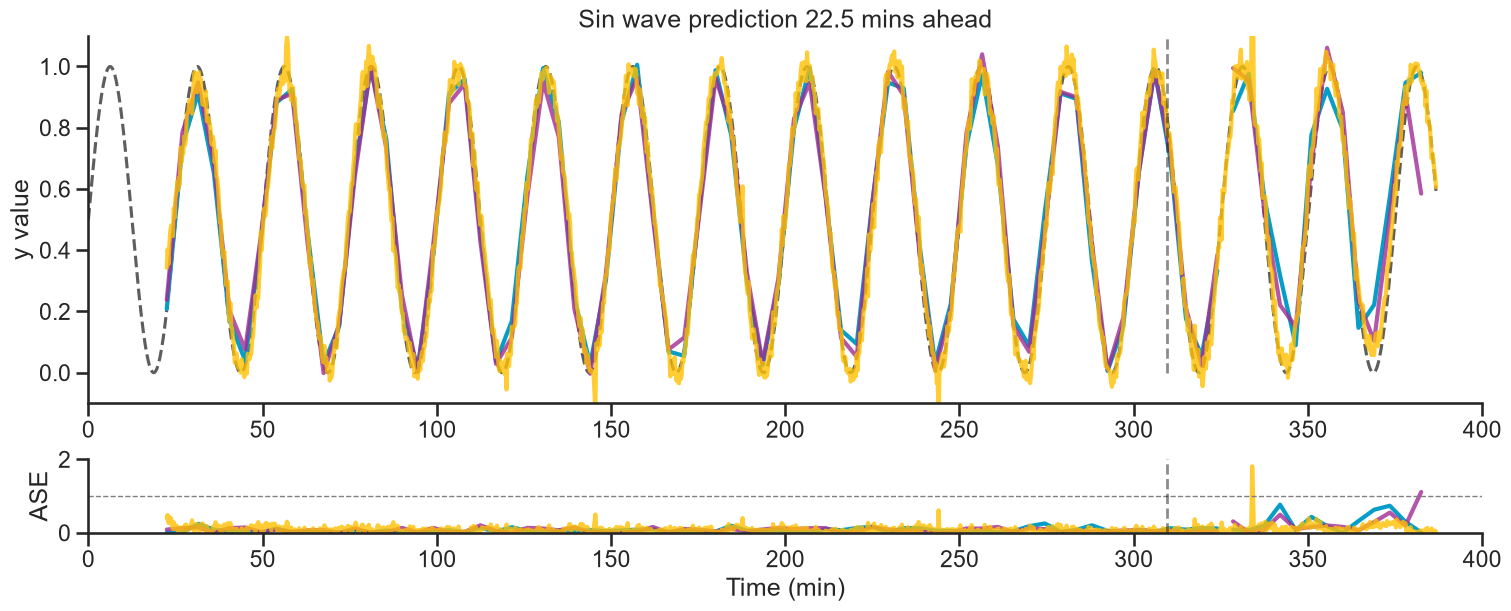

In [4]:

def plot_funct(task = task_df, predict_ahead = 1, save = save):
    #define fig paras
    fig1, axes = plt.subplots(2,1,figsize=(15,6), constrained_layout=True, gridspec_kw={'height_ratios': [5, 1]})

    #plot task 
    sns.lineplot(x = task.index/60, y = task_df['y value'], color = 'k', ax=axes[0], alpha = 0.7, linestyle = '--')

    #define location of data for low and high res
    data_files = {'low_res' : f'sine_wave_single_and_series_{predict_ahead*4.5}min_predictions.csv', 'high_res' : f'sine_wave_high_res_{predict_ahead*4.5}min_prediction.csv'}

    #define labels for splitting low res data
    labels = ['Single', 'Series']

    #defie dict for storing data
    data = {}

    #iterate through data files to extract and label data
    for k, v in data_files.items():
        data_df = pd.read_csv(data_path/data_files[k], index_col = 'Unnamed: 0')
        if 'Reactor' in data_df.columns:
            r = 0
            for i, group in data_df.groupby('Reactor'):
                plot_data(axes, group, a = alphas[r], colour = colours[r])
                data[labels[0]] = group
                r+=1
                
        else:
            r=2
            plot_data(axes, data_df, a = alphas[r], colour = colours[r])
            data[k] = data_df
                
    #set title
    axes[0].set_title(f"Sin wave prediction {predict_ahead*4.5} mins ahead")

    #set axes label
    axes[0].set_xlabel(r"")
    axes[1].set_xlabel(r"Time (min)")
    #def axis limits
    axes[1].set_ylim(0,2)
    axes[0].set_ylim(-0.1,1.1)
    axes[0].set_xlim(0,400)
    axes[1].set_xlim(0,400)

    #include horizontal line at 1 for ASE
    axes[1].axhline(y=1, color='gray', linestyle='--', linewidth=1)

    v_line = (data_df.loc[data_df['dataset'] == 'test', 'time (s)'].iloc[0]/60)+(predict_ahead-1)* 4.5

    #vlines for train test split
    axes[0].vlines(x = v_line, ymin = 0, ymax = 1.1, color = 'k', alpha = 0.5, linestyle = '--', linewidth=2)
    axes[1].vlines(x = v_line, ymin = 0, ymax = 2, color = 'k', alpha = 0.5, linestyle = '--', linewidth=2)


    axes[1].set_ylabel("ASE")

    sns.set_context('talk')
    sns.despine()

    if save:
        fig1.savefig(save_path/f'comparison_fig_sine_wave_{predict_ahead*4.5}min.svg', dpi = 900)
    plt.show()

for i in [1, 2, 3, 4, 5]:
    plot_funct(predict_ahead=i, save = True)
